# Explore sketch- and gene-based quantification in metagenomes

Notebook modified to make lab meeting figures ;).

The pancoding core project uses three different types of quantification:

* k-mer based coverage curves that fit to weighted_bp/intersect_bp from sketch intersection (species x metagenome) results;
* Gaussian mixture model peak finding in sketch intersection results;
* Mapping reads to (putative) species-specific gene sequences;

The mapping appoach is implemented in `2026-pancoding-core/scripts/summarize-mapping-depth-to-csv.py` and the k-mer-based approaches are both implemented in `2026-pancoding-core/scripts/isect-estimate-species-abundances.py`.

This notebook explores these approaches using results generated from the pancoding core scripts applied to simulated data (see the Snakefile).

## Using different references

The main motivation for this simulation approach was to evaluate what happened when the reference sequence being used for the quantification was divergent. So, we generate two collections of sequences, 'A' and 'B'. 'B' is ~4% divergent from 'A'. All of the reads are generated from 'A', and then some of the graphs below explore what happens when 'B' is used as the reference for quantification using those reads.

## Saturation curves:


$ y = G (1 - e^{-Cx}) $


In [1]:
import polars as pl
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

import os 
import numpy as np
from sklearn.mixture import GaussianMixture
import sourmash
import glob
import seaborn as sns
import collections
from scipy.stats import norm
import scipy

## for converting between reg coverage and k-mer coverage

per [link](https://bioinformatics.stackexchange.com/questions/2152/formula-for-k-mer-coverage)  and [link](https://www.biostars.org/p/221672/),

$C_𝑘 = { C (R - K + 1) \over R }$

so

$C = { C_k R \over (R- K + 1) } $

or

$C_{bp} = { C_k \times {\rm readlen} \over ({\rm readlen} - K + 1) } $

In [2]:
# base coverage:
def base_cov(kmer_cov, *, k, r):
    return kmer_cov * r / (r - k + 1)

In [3]:
import numpy as np

def concordance_correlation_coefficient(x, y):
    x = np.asarray(x)
    y = np.asarray(y)

    mean_x = np.mean(x)
    mean_y = np.mean(y)

    var_x = np.var(x)
    var_y = np.var(y)

    covariance = np.mean(
        (x - mean_x) * (y - mean_y)
    )

    return (
        2 * covariance /
        (var_x + var_y + (mean_x - mean_y)**2)
    )

## Saturation curves when using different references

Q: What do the k-mer coverage curves look like when the "wrong" (divergent) reference is used?

A: curve details are different but curve shape and abundance estimation is same.

In [4]:
# read k-mer collector's curve info
kmer_df = pl.read_csv('pure/reads.isect.kmer_stats.csv')
pang_kmer_df = pl.read_csv('pang_90_10/reads.isect.kmer_stats.csv')

In [5]:
def coverage_curve(x, G, C):
    return G*(1 - np.exp(-C*x))

def do_covcurve_fit(contain_df, *, fn=coverage_curve, p0=None):
    "Fit to given function, which takes two parameters, G and C. Return fit values & params."

    if p0 is None:
        p0 = (max(contain_df['weighted_bp']), .001)

    popt, pcov = scipy.optimize.curve_fit(fn, contain_df['weighted_bp'], contain_df['intersect_bp'], p0)
    G, C = popt

    y = np.asarray(contain_df['weighted_bp'])
    yfit = coverage_curve(y, G, C)

    # residual sum of squares                                                       
    ss_res = np.sum((y - yfit) ** 2)
    # total sum of squares                                                          
    ss_tot = np.sum((y - np.mean(y)) ** 2)
    # r-squared                                                                     
    r2 = 1 - (ss_res / ss_tot)

    return yfit, (G, C), r2


def covcurve_estimate_values(intersect_bp, weighted_bp, gsize, cexp):
    fit_breadth = intersect_bp / gsize
    fit_depth = weighted_bp / gsize
    curve_breadth = coverage_curve(weighted_bp, gsize, cexp) / gsize

    return fit_breadth, fit_depth, curve_breadth


## Plot a collector's curve

Text(0, 0.5, 'amount of genome sampled > 0 (or, num distinct k-mers)')

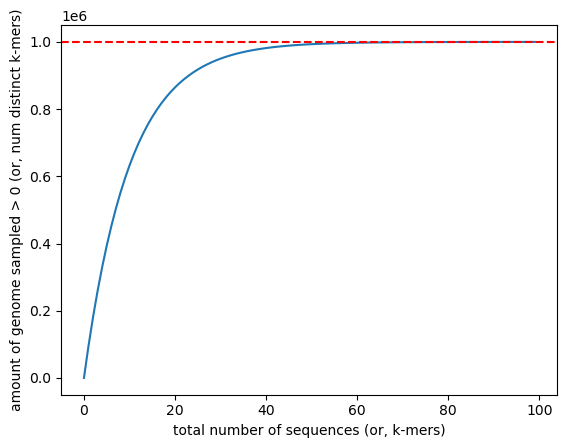

In [6]:
x = np.arange(0, 100, 1)
y = coverage_curve(x, 1e6, .1)

plt.plot(x, y)
plt.axhline(1e6, linestyle='--', color='red')
plt.xlabel('total number of sequences (or, k-mers)')
plt.ylabel('amount of genome sampled > 0 (or, num distinct k-mers)')

/group/datalabgrp/ctbrown/2025-grist-annie/.snakemake/conda/ab4c18c32e39b7f9ba11a10bc8c18bcf_/lib/python3.12/site-packages/polars/series/series.py:1571: RuntimeWarning: overflow encountered in exp
  lambda out: ufunc(*args, out=out, dtype=dtype_char, **kwargs),


Text(0.5, 1.0, 'Coverage saturation curve fit')

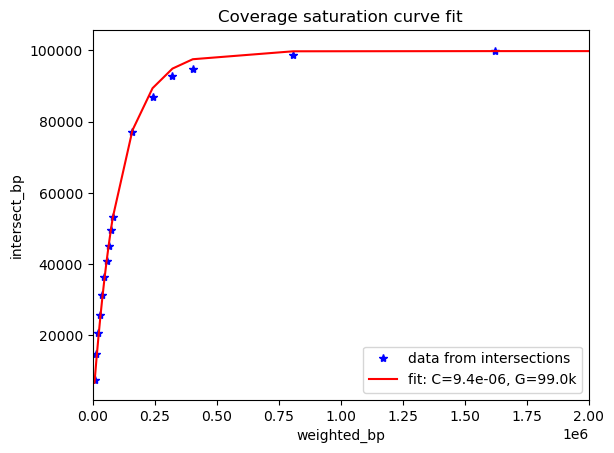

In [7]:
xx_df = kmer_df.filter(pl.col('species') == 'a').sort('weighted_bp')
plt.plot(xx_df['weighted_bp'], xx_df['intersect_bp'], 'b*', label='data from intersections')

yfit, (G, C), r2 = do_covcurve_fit(xx_df)
plt.plot(xx_df['weighted_bp'], yfit, 'r-', label=f'fit: C={C:.2g}, G={G//1000}k')

plt.xlim(0, 2e6)
plt.xlabel('weighted_bp')
plt.ylabel('intersect_bp')
plt.legend(loc='lower right')
plt.title('Coverage saturation curve fit')

Text(0.5, 1.0, 'Coverage curve fit with good & divergent references')

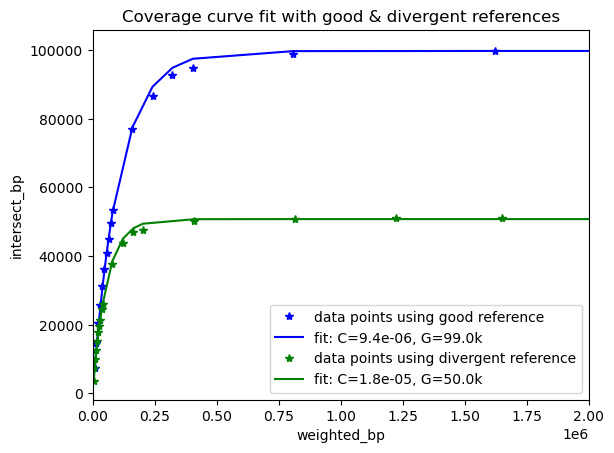

In [8]:
xx_df = kmer_df.filter(pl.col('species') == 'a').sort('weighted_bp')
plt.plot(xx_df['weighted_bp'], xx_df['intersect_bp'], 'b*', label='data points using good reference')

yfit_xx, (G, C), r2 = do_covcurve_fit(xx_df)
plt.plot(xx_df['weighted_bp'], yfit_xx, 'b-', label=f'fit: C={C:.2g}, G={G//1000}k')

yy_df = kmer_df.filter(pl.col('species') == 'b').sort('weighted_bp')
plt.plot(yy_df['weighted_bp'], yy_df['intersect_bp'], 'g*', label='data points using divergent reference')

yfit_yy, (Gy, Cy), r2y = do_covcurve_fit(yy_df)
plt.plot(yy_df['weighted_bp'], yfit_yy, 'g-', label=f'fit: C={Cy:.2g}, G={Gy//1000}k')



plt.xlim(0, 2e6)
plt.xlabel('weighted_bp')
plt.ylabel('intersect_bp')
plt.legend(loc='lower right')
plt.title('Coverage curve fit with good & divergent references')

/group/datalabgrp/ctbrown/2025-grist-annie/.snakemake/conda/ab4c18c32e39b7f9ba11a10bc8c18bcf_/lib/python3.12/site-packages/polars/series/series.py:1571: RuntimeWarning: overflow encountered in multiply
  lambda out: ufunc(*args, out=out, dtype=dtype_char, **kwargs),


Text(0.5, 1.0, 'Coverage saturation curve fit to pangenome a+b')

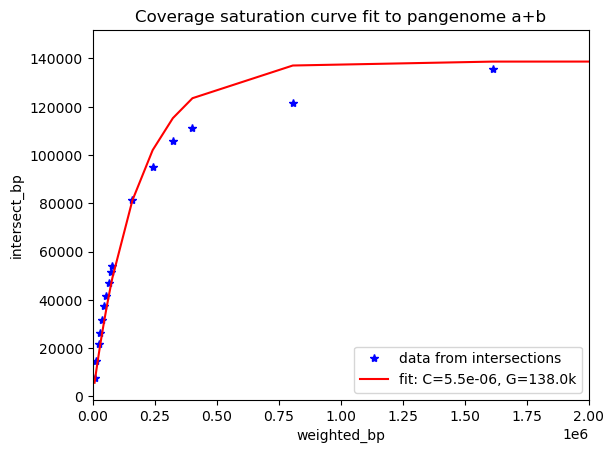

In [9]:
xx_df = pang_kmer_df.filter(pl.col('species') == 'a+b').sort('weighted_bp')
plt.plot(xx_df['weighted_bp'], xx_df['intersect_bp'], 'b*', label='data from intersections')

yfit, (G, C), r2 = do_covcurve_fit(xx_df)
plt.plot(xx_df['weighted_bp'], yfit, 'r-', label=f'fit: C={C:.2g}, G={G//1000}k')

plt.xlim(0, 2e6)
plt.xlabel('weighted_bp')
plt.ylabel('intersect_bp')
plt.legend(loc='lower right')
plt.title('Coverage saturation curve fit to pangenome a+b')

## Load combined coverage estimates

Q: how do coverage estimates vary with the combined k-mer estimates (cov curve and gmm approaches) when using the wrong reference?

A: the estimates are pretty similar; the reference doesn't seem to matter as long as it's reasonably close.

In [10]:
abund_df = (
    pl.read_csv('pure/reads.isect.abund.csv')
    .with_columns(
        cov=pl.col('metag').str.split('-').list.get(1).cast(pl.Float32)
    )
)
abund_df['method'].unique()

pang_abund_df = (
    pl.read_csv('pang_90_10/reads.isect.abund.csv')
    .with_columns(
        cov=pl.col('metag').str.split('-').list.get(1).cast(pl.Float32)
    )
)

abund_df['method'].unique()


method
str
"""composite_k"""
"""covcurve_round2"""
"""gmm"""
"""covcurve_round1"""
"""composite"""


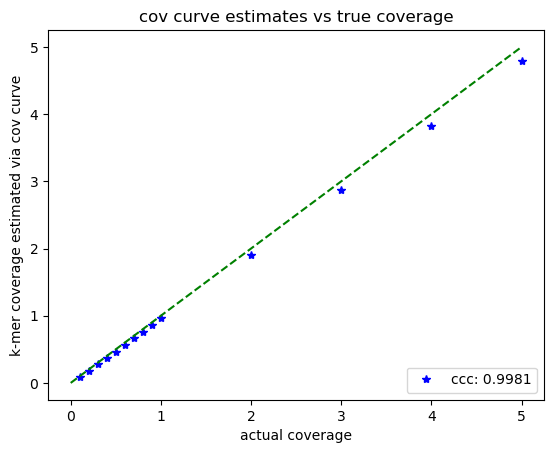

In [11]:
aa_df = abund_df.filter((pl.col('species') == 'a') & (pl.col('method') == 'composite') & (pl.col('cov') < 10))
ccc = concordance_correlation_coefficient(aa_df['cov'], aa_df['abund'])

plt.plot(aa_df['cov'], aa_df['abund'], 'b*', label=f'ccc: {ccc:.4f}')
plt.plot([0, 5], [0, 5], 'g--')
plt.xlabel('actual coverage')
plt.ylabel('k-mer coverage estimated via cov curve')
plt.title('cov curve estimates vs true coverage')
plt.legend(loc='lower right')

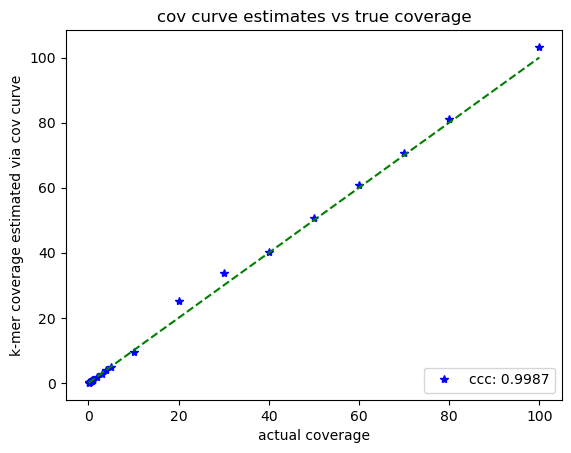

In [12]:
aa_df = abund_df.filter((pl.col('species') == 'a') & (pl.col('method') == 'composite'))
ccc = concordance_correlation_coefficient(aa_df['cov'], aa_df['abund'])

plt.plot(aa_df['cov'], aa_df['abund'], 'b*', label=f'ccc: {ccc:.4f}')
plt.plot([0, 100], [0, 100], 'g--')
plt.xlabel('actual coverage')
plt.ylabel('k-mer coverage estimated via cov curve')
plt.title('cov curve estimates vs true coverage')
plt.legend(loc='lower right')

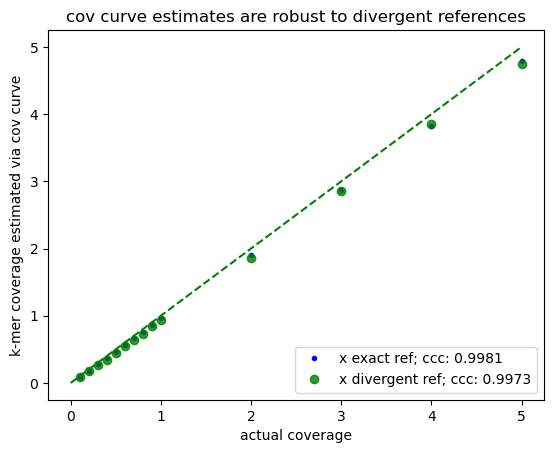

In [13]:
aa_df = abund_df.filter((pl.col('species') == 'a') & (pl.col('method') == 'composite') & (pl.col('cov') < 10))
bb_df = abund_df.filter((pl.col('species') == 'b') & (pl.col('method') == 'composite') & (pl.col('cov') < 10))

ccc = concordance_correlation_coefficient(aa_df['cov'], aa_df['abund'])
ccc2 = concordance_correlation_coefficient(bb_df['cov'], bb_df['abund'])

plt.plot(aa_df['cov'], aa_df['abund'], 'b.', label=f'x exact ref; ccc: {ccc:.4f}')
plt.plot(bb_df['cov'], bb_df['abund'], 'go', label=f'x divergent ref; ccc: {ccc2:.4f}', alpha=0.8)

plt.plot([0, 5], [0, 5], 'g--')
plt.xlabel('actual coverage')
plt.ylabel('k-mer coverage estimated via cov curve')
plt.title('cov curve estimates are robust to divergent references')
plt.legend(loc='lower right')

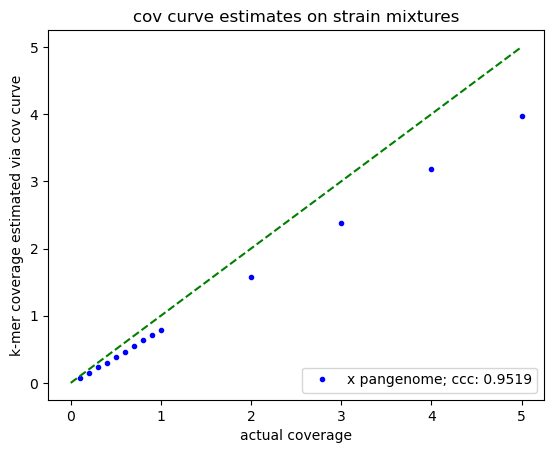

In [50]:
aa_df = pang_abund_df.filter((pl.col('species') == 'a+b') & (pl.col('method') == 'composite') & (pl.col('cov') < 10))

ccc = concordance_correlation_coefficient(aa_df['cov'], aa_df['abund'])
#ccc2 = concordance_correlation_coefficient(bb_df['cov'], bb_df['abund'])

plt.plot(aa_df['cov'], aa_df['abund'], 'b.', label=f'x pangenome; ccc: {ccc:.4f}')
#plt.plot(bb_df['cov'], bb_df['abund'], 'go', label=f'x divergent ref; ccc: {ccc2:.4f}', alpha=0.8)

plt.plot([0, 5], [0, 5], 'g--')
plt.xlabel('actual coverage')
plt.ylabel('k-mer coverage estimated via cov curve')
plt.title('cov curve estimates on strain mixtures')
plt.legend(loc='lower right')

In [15]:
def find_best_bic(values, *, verbose=False):
    # calculate best num components based on Bayesian Information Criterion score:
    bics = dict()
    for n_components in range(1, 6):
        clf = GaussianMixture(n_components=n_components, covariance_type="spherical")
        labels = clf.fit(values).predict(values)
        bics[n_components] = round(float(clf.bic(values)), 2)

    bics = list(bics.items())
    bics.sort(key=lambda x: x[1])
    best_n = bics[0][0]
    if verbose:
        print('BICS:', best_n, bics)

    return best_n

In [16]:
GMM_Peak = collections.namedtuple('GMM_Peak', ['idx', 'mean', 'weight', 'covariance'])

def gmm_fit(values, *, num_components=None, verbose=False):
    if num_components is None:
        num_components = find_best_bic(values, verbose=verbose)
    
    clf = GaussianMixture(n_components=num_components, covariance_type="spherical")
    clf.fit(values)

    orig_peaks = []
    for i in range(num_components):
        mean = float(clf.means_[i][0])
        weight = float(clf.weights_[i])
        cov = float(clf.covariances_[i])
        peak = GMM_Peak(i, mean, weight, cov)
        orig_peaks.append(peak)

    # choose largest mean with weight above 0.1
    peaks = [ p for p in orig_peaks if p.weight >= 0.1]
    peaks.sort(key=lambda x: -x.mean)
    best_peak = peaks[0]

    if verbose:
        for peak in orig_peaks:
            ch = ''
            if peak == best_peak:
                ch = '*'
            print(f'{ch}{peak.idx}: {peak.mean:.1f} {peak.weight:.3f} {peak.covariance:.3f}')

    return best_peak


In [17]:
def load_fit_plot_isect(species, metag, *, do_fit=True, bins=50, num_components=None, verbose=True, estimate=None, title=None):
    siglist = list(sourmash.load_file_as_signatures('pure/reads.isect.sig.zip'))
    found = False
    name = f"{species}.x.{metag} isect"
    for ss in siglist:
        if name == ss.name:
            found = True
            break

    assert found

    values = np.array(list(ss.minhash.hashes.values())).reshape(-1, 1)

     # track hashval abundance distribution
    counts_d = collections.defaultdict(int)
    # track abundance distribution, too
    counter = collections.Counter()

    for hashval, abund in ss.minhash.hashes.items():
        counts_d[hashval] += abund
        counter[abund] += 1

    all_counts = list(counts_d.values())
    counts_dist = list(counter.items())
    sum_hist = sum(counter.values())
    max_range = max(counter.values())
    min_range = 0

    # find count that covers 95% of distribution.
    sofar = 0
    for k, v in sorted(counts_dist):
        sofar += v
        if sofar >= 0.99*sum_hist:
            max_range = 2*k
            break

    fig, ax1 = plt.subplots(nrows=1, ncols=1, figsize=(8, 5))
    sns.histplot(all_counts, ax=ax1,
                 binrange=(min_range, max_range),
                 bins=bins, kde=False, stat='count')

    if do_fit:
        best_peak = gmm_fit(values, num_components=num_components, verbose=verbose)
        ax1.axvline(best_peak.mean, linestyle='-.', color='red')
    
        zz = len([ v for v in values if v > min_range and v < max_range ])
    
        bin_width = (max_range - min_range) / bins
    
        x_axis = np.arange(min_range, max_range, 0.1)
        y_axis0 = norm.pdf(x_axis, best_peak.mean, np.sqrt(best_peak.covariance)) * best_peak.weight * zz * bin_width
        ax1.plot(x_axis, y_axis0, color='red')
    
        if estimate:
            plt.axvline(estimate, color='r', linestyle='--')

    if title is None:
        title = f'{species}.x.{metag}'
    fig.suptitle(title)

    plt.show()

BICS: 2 [(2, 7414.72), (4, 7423.55), (3, 7439.77), (5, 7443.91), (1, 7973.81)]
*0: 70.4 0.871 90.487
1: 23.1 0.129 228.820


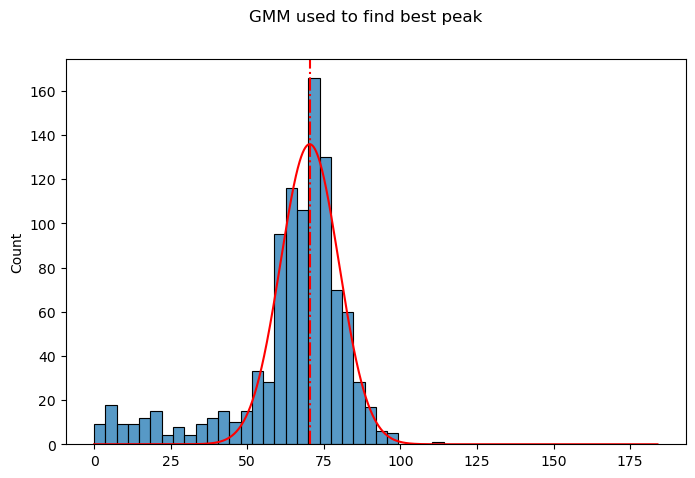

In [18]:
species = 'a'
metag='R-80'
est_df = abund_df.filter(
    (pl.col('species') == species) & (pl.col('metag') == metag) & (pl.col('method') == 'gmm')
)
assert len(est_df) == 1

estimate = estimate=est_df['cov'].item()
load_fit_plot_isect(species, metag, title='GMM used to find best peak')

In [19]:
abund_df['metag'].unique()

metag
str
"""R-0.7"""
"""R-3"""
"""R-40"""
"""R-0.8"""
"""R-100"""
…
"""R-30"""
"""R-0.1"""
"""R-1"""


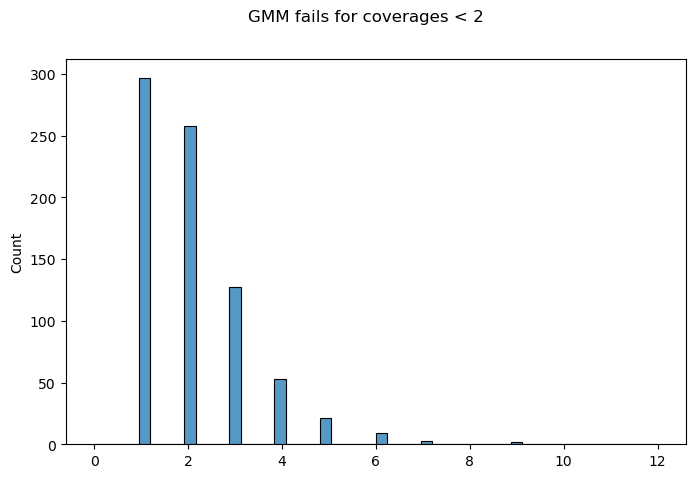

In [20]:
load_fit_plot_isect("a", "R-2", title='GMM fails for coverages < 2', do_fit=False)

BICS: 2 [(2, 3810.66), (3, 3814.86), (4, 3823.47), (5, 3839.66), (1, 4094.44)]
0: 23.6 0.139 247.779
*1: 70.5 0.861 89.089


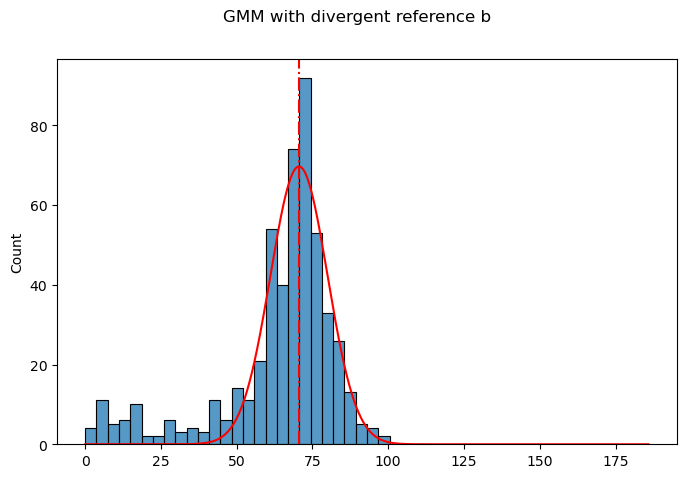

In [21]:
species = 'b'
metag='R-80'
est_df = abund_df.filter(
    (pl.col('species') == species) & (pl.col('metag') == metag) & (pl.col('method') == 'gmm')
)
assert len(est_df) == 1

estimate = estimate=est_df['cov'].item()
load_fit_plot_isect(species, metag, title='GMM with divergent reference b')

In [22]:
def load_fit_plot_isect2(species, metag, *, do_fit=True, bins=50, num_components=None, verbose=True, estimate=None, title=None):
    siglist = list(sourmash.load_file_as_signatures('pang_90_10/reads.isect.sig.zip'))
    found = False
    name = f"{species}.x.{metag} isect"
    for ss in siglist:
        if name == ss.name:
            found = True
            break

    assert found

    values = np.array(list(ss.minhash.hashes.values())).reshape(-1, 1)

     # track hashval abundance distribution
    counts_d = collections.defaultdict(int)
    # track abundance distribution, too
    counter = collections.Counter()

    for hashval, abund in ss.minhash.hashes.items():
        counts_d[hashval] += abund
        counter[abund] += 1

    all_counts = list(counts_d.values())
    counts_dist = list(counter.items())
    sum_hist = sum(counter.values())
    max_range = max(counter.values())
    min_range = 0

    # find count that covers 95% of distribution.
    sofar = 0
    for k, v in sorted(counts_dist):
        sofar += v
        if sofar >= 0.99*sum_hist:
            max_range = 2*k
            break

    fig, ax1 = plt.subplots(nrows=1, ncols=1, figsize=(8, 5))
    sns.histplot(all_counts, ax=ax1,
                 binrange=(min_range, max_range),
                 bins=bins, kde=False, stat='count')

    if do_fit:
        best_peak = gmm_fit(values, num_components=num_components, verbose=verbose)
        ax1.axvline(best_peak.mean, linestyle='-.', color='red')
    
        zz = len([ v for v in values if v > min_range and v < max_range ])
    
        bin_width = (max_range - min_range) / bins
    
        x_axis = np.arange(min_range, max_range, 0.1)
        y_axis0 = norm.pdf(x_axis, best_peak.mean, np.sqrt(best_peak.covariance)) * best_peak.weight * zz * bin_width
        ax1.plot(x_axis, y_axis0, color='red')
    
        if estimate:
            plt.axvline(estimate, color='r', linestyle='--')

    if title is None:
        title = f'{species}.x.{metag}'
    fig.suptitle(title)

    plt.show()

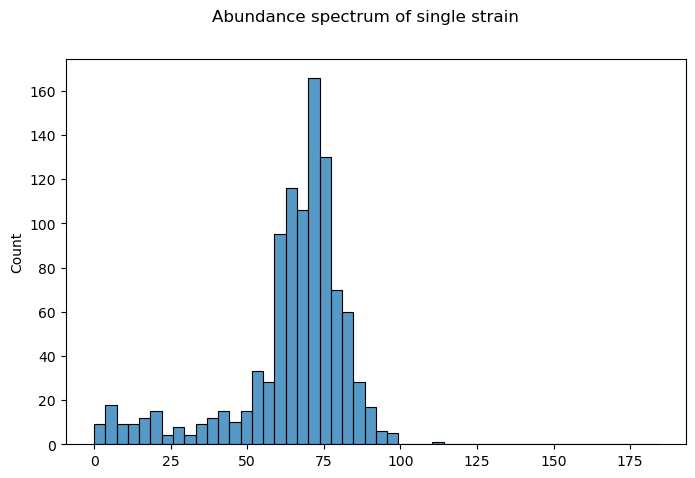

In [52]:
load_fit_plot_isect("a", 'R-80', do_fit=False, title='Abundance spectrum of single strain')

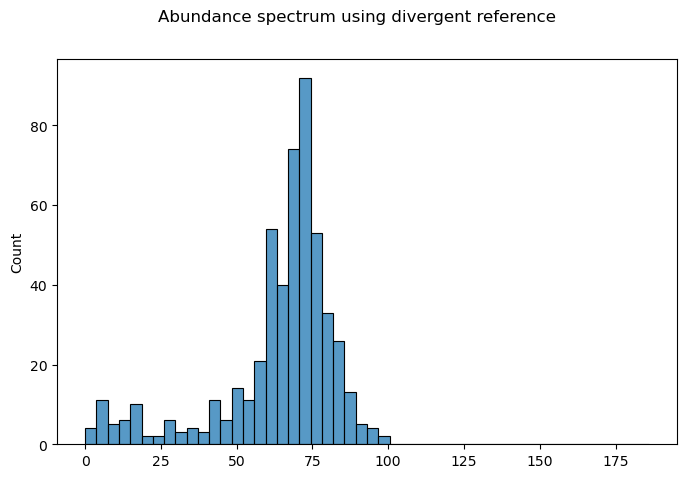

In [53]:
load_fit_plot_isect("b", 'R-80', do_fit=False, title='Abundance spectrum using divergent reference')

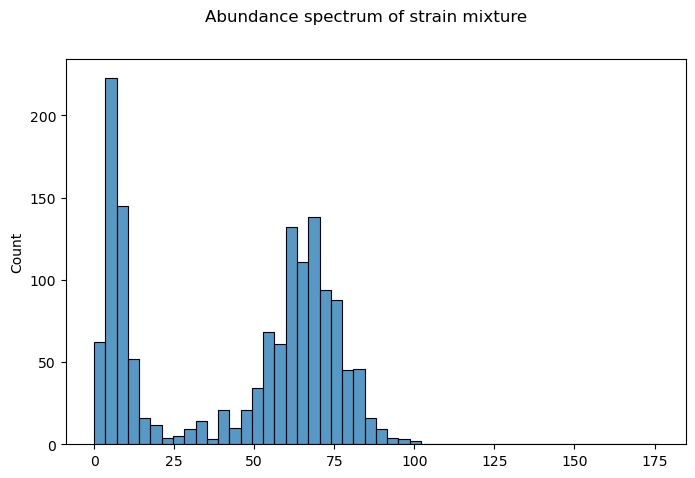

In [51]:
load_fit_plot_isect2("a+b", 'R-80', do_fit=False, title='Abundance spectrum of strain mixture')

BICS: 3 [(3, 10716.4), (4, 10732.75), (5, 10754.95), (2, 10827.81), (1, 12689.78)]
*0: 68.0 0.393 60.182
1: 7.1 0.340 9.895
2: 58.4 0.267 321.872


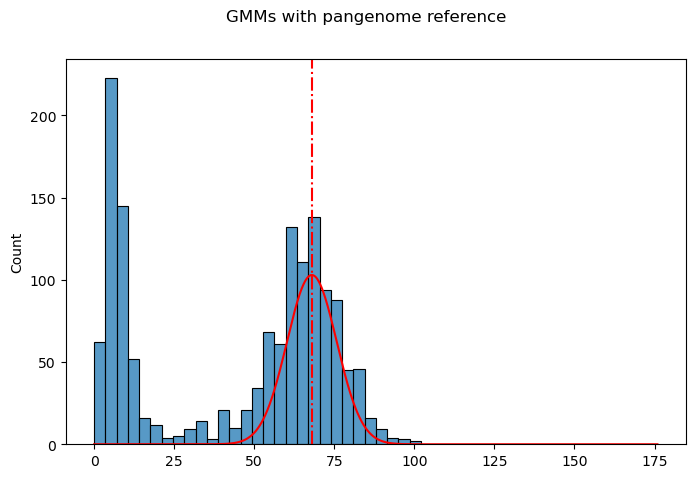

In [23]:
load_fit_plot_isect2("a+b", 'R-80', title='GMMs with pangenome reference')

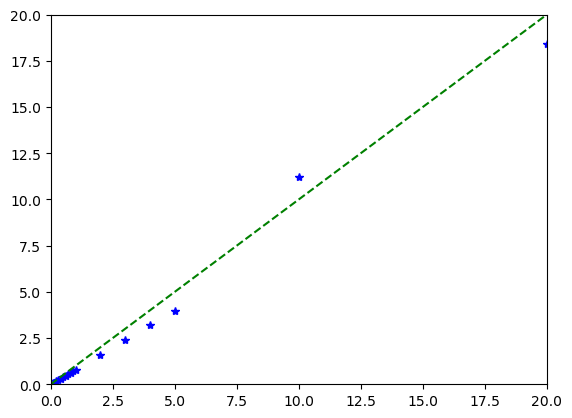

In [24]:
xx_df = pang_abund_df.filter(pl.col('method') == 'composite')
plt.plot(xx_df['cov'], xx_df['abund'], 'b*')
plt.xlim(0, 20)
plt.ylim(0, 20)
plt.plot([0, 20], [0, 20], 'g--')

In [25]:
min(abund_df.filter(pl.col('method') == 'gmm')['cov'])

10.0

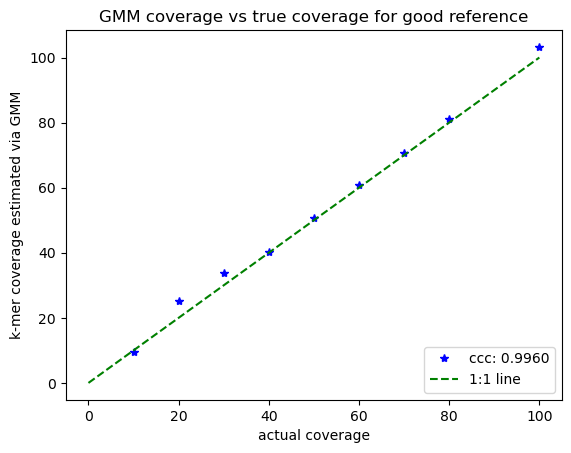

In [55]:
aa_df = abund_df.filter((pl.col('species') == 'a') & (pl.col('method') == 'composite') & (pl.col('cov') >= 10))
ccc = concordance_correlation_coefficient(aa_df['cov'], aa_df['abund'])
plt.plot(aa_df['cov'], aa_df['abund'], 'b*', label=f'ccc: {ccc:.4f}')
plt.plot([0, 100], [0, 100], 'g--', label='1:1 line')
plt.xlabel('actual coverage')
plt.ylabel('k-mer coverage estimated via GMM')
plt.title('GMM coverage vs true coverage for good reference')
plt.legend(loc='lower right')

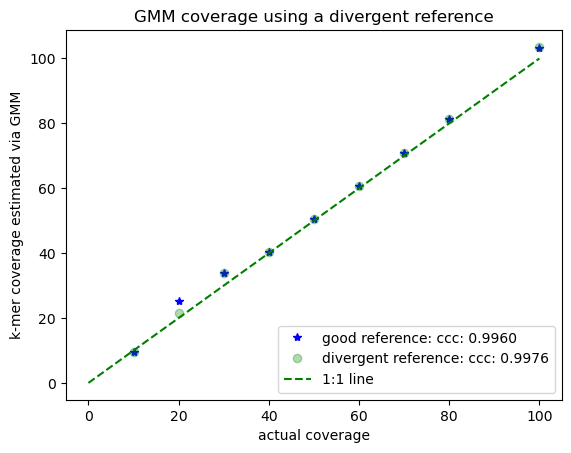

In [63]:
aa_df = abund_df.filter((pl.col('species') == 'a') & (pl.col('method') == 'composite') & (pl.col('cov') >= 10))
ccc = concordance_correlation_coefficient(aa_df['cov'], aa_df['abund'])
plt.plot(aa_df['cov'], aa_df['abund'], 'b*', label=f'good reference: ccc: {ccc:.4f}')

bb_df = abund_df.filter((pl.col('species') == 'b') & (pl.col('method') == 'composite') & (pl.col('cov') >= 10))
ccc2 = concordance_correlation_coefficient(bb_df['cov'], bb_df['abund'])
plt.plot(bb_df['cov'], bb_df['abund'], 'go', alpha=0.3, label=f'divergent reference: ccc: {ccc2:.4f}')

plt.plot([0, 100], [0, 100], 'g--', label='1:1 line')
plt.xlabel('actual coverage')
plt.ylabel('k-mer coverage estimated via GMM')
plt.title('GMM coverage using a divergent reference')
plt.legend(loc='lower right')

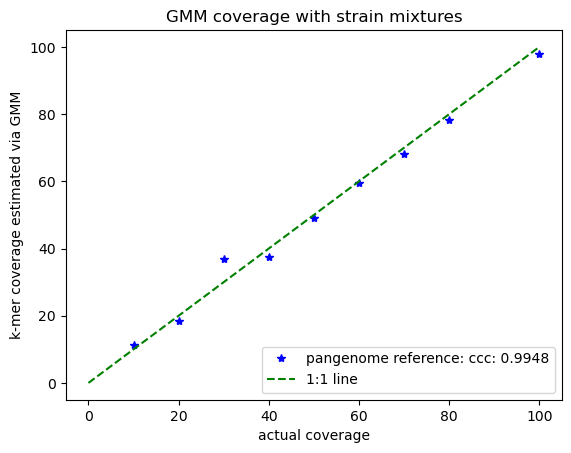

In [65]:
aa_df = pang_abund_df.filter((pl.col('species') == 'a+b') & (pl.col('method') == 'composite') & (pl.col('cov') >= 10))
ccc = concordance_correlation_coefficient(aa_df['cov'], aa_df['abund'])
plt.plot(aa_df['cov'], aa_df['abund'], 'b*', label=f'pangenome reference: ccc: {ccc:.4f}')


plt.plot([0, 100], [0, 100], 'g--', label='1:1 line')
plt.xlabel('actual coverage')
plt.ylabel('k-mer coverage estimated via GMM')
plt.title('GMM coverage with strain mixtures')
plt.legend(loc='lower right')

## Compare k-mer abundance estimates vs different references for composite k-mer estimates

Q: How good is the composite k-mer abundance estimate (low coverage via coverage curve, high coverage via gaussian mixture model)?

A: systematically low, but still pretty darned good.

Text(0.5, 1.0, 'composite k-mer estimates of coverage')

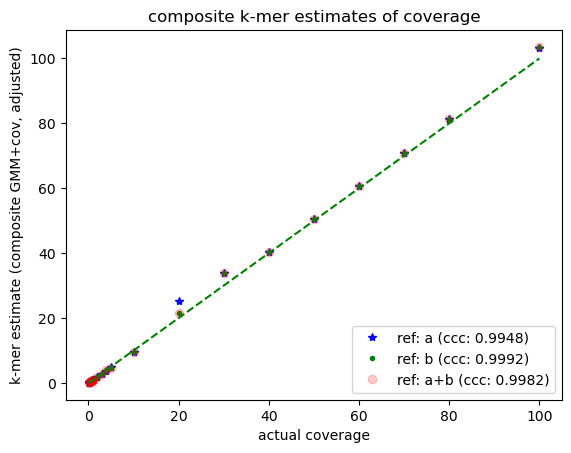

In [74]:
aa_df = abund_df.filter((pl.col('species') == 'a') & (pl.col('method') == 'composite'))
bb_df = abund_df.filter((pl.col('species') == 'b') & (pl.col('method') == 'composite'))
cc_df = pang_abund_df.filter((pl.col('species') == 'a+b') & (pl.col('method') == 'composite'))

ccc1 = concordance_correlation_coefficient(aa_df['cov'], aa_df['abund'])
plt.plot(aa_df['cov'], aa_df['abund'], 'b*', label=f'ref: a (ccc: {ccc:.4f})')
ccc2 = concordance_correlation_coefficient(bb_df['cov'], bb_df['abund'])
plt.plot(bb_df['cov'], bb_df['abund'], 'g.', label=f'ref: b (ccc: {ccc2:.4f})')
ccc3 = concordance_correlation_coefficient(cc_df['cov'], cc_df['abund'])
plt.plot(bb_df['cov'], bb_df['abund'], 'ro', alpha=0.2, label=f'ref: a+b (ccc: {ccc3:.4f})')

plt.plot([0, 100], [0, 100], 'g--')
plt.xlabel('actual coverage')
plt.ylabel('k-mer estimate (composite GMM+cov, adjusted)')
plt.legend(loc='lower right')
plt.title('composite k-mer estimates of coverage')

(0.0, 5.0)

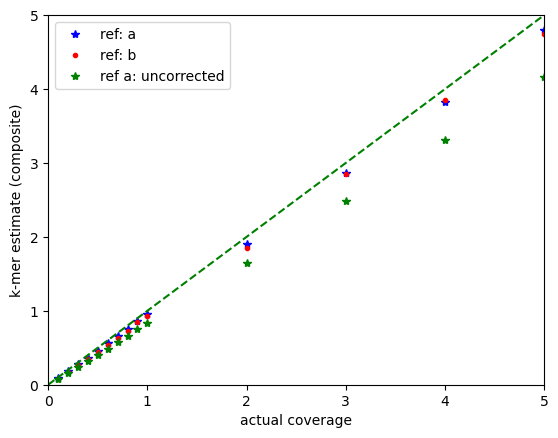

In [29]:
aa_df = abund_df.filter((pl.col('species') == 'a') & (pl.col('method') == 'composite'))
bb_df = abund_df.filter((pl.col('species') == 'b') & (pl.col('method') == 'composite'))

plt.plot(aa_df['cov'], aa_df['abund'], 'b*', label='ref: a')
plt.plot(bb_df['cov'], bb_df['abund'], 'r.', label='ref: b')

uncorrected_aa_df = abund_df.filter((pl.col('species') == 'a') & (pl.col('method') == 'composite_k'))
plt.plot(aa_df['cov'], uncorrected_aa_df['abund'], 'g*', label='ref a: uncorrected')

plt.plot([0, 100], [0, 100], 'g--')
plt.xlabel('actual coverage')
plt.ylabel('k-mer estimate (composite)')
plt.legend(loc='upper left')
plt.xlim(0, 5)
plt.ylim(0, 5)

## Compare k-mer abundance estimates vs different references for covcurve specifically

Q: How good are the coverage curve-based estimates?

A: systematically low, but still pretty darned good.

(Note that for _real_ data we have low-abundance strains that make an appearance, so this is systematically way too low on real data at high coverage, which is why we went with GMMs for > 10x.)

Text(0.5, 1.0, 'coverage curve-based k-mer estimates only')

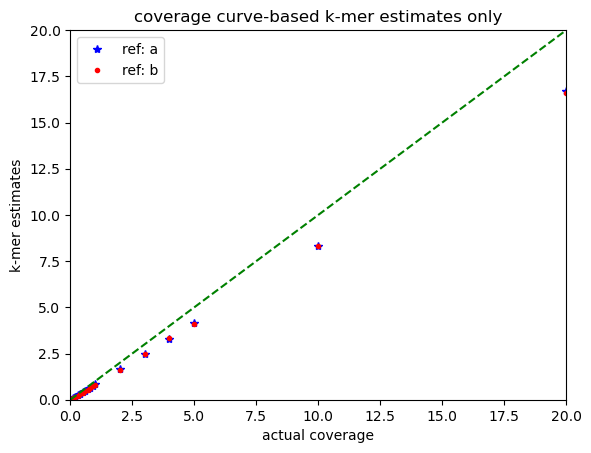

In [30]:
aa_df = abund_df.filter((pl.col('species') == 'a') & (pl.col('method') == 'covcurve_round2'))
bb_df = abund_df.filter((pl.col('species') == 'b') & (pl.col('method') == 'covcurve_round2'))

plt.plot(aa_df['cov'], aa_df['abund'], 'b*', label='ref: a')
plt.plot(bb_df['cov'], bb_df['abund'], 'r.', label='ref: b')
plt.xlim(0, 20)
plt.ylim(0, 20)
plt.plot([0, 100], [0, 100], 'g--')

plt.xlabel('actual coverage')
plt.ylabel('k-mer estimates')
plt.legend(loc='upper left')
plt.title('coverage curve-based k-mer estimates only')

## Load in the mapping abundances for both references

Mapping-based abundance is calculated here against all genes; reads are only from genome A, but mapped to genome A and B.

In [40]:
mapping_a_df = pl.read_csv('pure/mapping.a.csv').with_columns(
    species=pl.lit("a"),
    cov=pl.col('metag').str.split('-').list.get(1).cast(pl.Float32),
)
mapping_b_df = pl.read_csv('pure/mapping.b.csv').with_columns(
    species=pl.lit("b"),
    cov=pl.col('metag').str.split('-').list.get(1).cast(pl.Float32),
)
pang_mapping_df = pl.read_csv('pang_90_10/mapping.a+b.csv').with_columns(
    species=pl.lit("a+b"),
    cov=pl.col('metag').str.split('-').list.get(1).cast(pl.Float32),
)

In [41]:
mapping_a_df

metag,gene,len,hits,breadth,depth_all,depth_cov,species,cov
str,str,i64,i64,f64,f64,f64,str,f32
"""R-0.1""","""A_72""",925,100,0.108108,0.108108,1.0,"""a""",0.1
"""R-0.1""","""A_97""",925,0,0.0,0.0,NaN,"""a""",0.1
"""R-0.1""","""A_63""",925,0,0.0,0.0,NaN,"""a""",0.1
"""R-0.1""","""A_86""",925,100,0.108108,0.108108,1.0,"""a""",0.1
"""R-0.1""","""A_93""",925,200,0.216216,0.216216,1.0,"""a""",0.1
…,…,…,…,…,…,…,…,…
"""R-100""","""A_59""",925,924,0.998919,98.135135,98.241342,"""a""",100.0
"""R-100""","""A_51""",925,924,0.998919,101.435676,101.545455,"""a""",100.0
"""R-100""","""A_79""",925,924,0.998919,105.525405,105.63961,"""a""",100.0


## How good is mapping based coverage?

Q: How well does mapping-based coverage estimate true coverage?

A: pretty darned well, but is always an overestimate!?

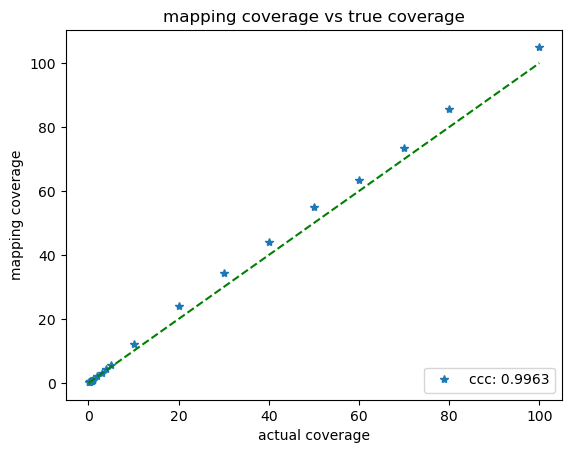

In [33]:
gene_df = (
    mapping_a_df
    .filter(pl.col('gene') == "A_1")
    .select(['metag', 'species', 'depth_all', 'cov'])
)

res = concordance_correlation_coefficient(gene_df['cov'], gene_df['depth_all'])

plt.plot(gene_df['cov'], gene_df['depth_all'], '*', label=f'ccc: {res:.4f}')
plt.plot([0, 100], [0, 100], 'g--')
plt.xlabel('actual coverage')
plt.ylabel('mapping coverage')
plt.title('mapping coverage vs true coverage')
plt.legend(loc='lower right')

0.9993679297805432


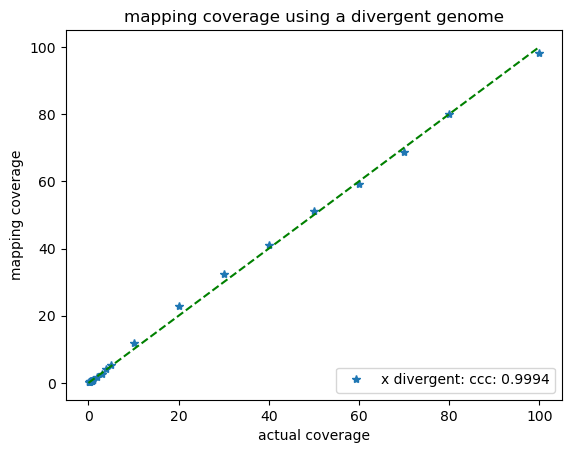

In [36]:
gene_df = (
    mapping_b_df
    .filter(pl.col('gene') == "B_1")
    .select(['metag', 'species', 'depth_all', 'cov'])
)

res = concordance_correlation_coefficient(gene_df['cov'], gene_df['depth_all'])

plt.plot(gene_df['cov'], gene_df['depth_all'], '*', label=f'x divergent: ccc: {res:.4f}')
plt.plot([0, 100], [0, 100], 'g--')
plt.xlabel('actual coverage')
plt.ylabel('mapping coverage')
plt.title('mapping coverage using a divergent genome')
plt.legend(loc='lower right')
print(res)

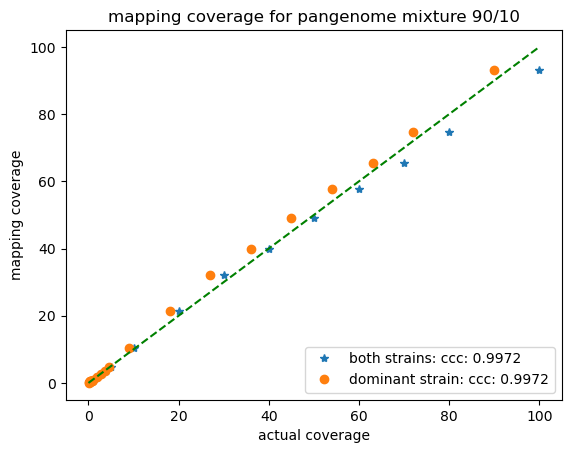

In [48]:
gene_df = (
    pang_mapping_df
    .filter(pl.col('gene') == "A_1")
    .select(['metag', 'species', 'depth_all', 'cov'])
)

res = concordance_correlation_coefficient(gene_df['cov'], gene_df['depth_all'])
res2 = concordance_correlation_coefficient(gene_df['cov'] * 0.9, gene_df['depth_all'])


plt.plot(gene_df['cov'], gene_df['depth_all'], '*', label=f'both strains: ccc: {res:.4f}')
plt.plot(gene_df['cov'] * 0.9, gene_df['depth_all'], 'o', label=f'dominant strain: ccc: {res:.4f}')
plt.plot([0, 100], [0, 100], 'g--')
plt.xlabel('actual coverage')
plt.ylabel('mapping coverage')
plt.title('mapping coverage for pangenome mixture 90/10')
plt.legend(loc='lower right')

## Combine k-mer estimation and mapping estimation into common data frame

Now let's compare mapping and k-mer based estimates...

In [ ]:

aa_df = abund_df.filter((pl.col('species') == 'a') & (pl.col('method') == 'composite'))

gene_a_df = (
    mapping_a_df
    .filter(pl.col('gene') == "A_1")
    .select(['metag', 'species', 'depth_all'])
)
combo_a_df = gene_df.join(aa_df, on=['metag', 'species'], how='inner')
combo_a_df

## Plot k-mer estimation and mapping abundance, with reads 'a' & genome 'a'

In [ ]:
aa_df = abund_df.filter((pl.col('species') == 'a') & (pl.col('method').is_in(['composite', 'composite_k'])))

gene_a_df = (
    mapping_a_df
    .filter(pl.col('gene') == "A_1")
    .select(['metag', 'species', 'depth_all'])
)
combo_a_df = gene_a_df.join(aa_df, on=['metag', 'species'], how='inner')

corrected_df = combo_a_df.filter(pl.col('method') == 'composite')
plt.plot(corrected_df['depth_all'], corrected_df['abund'], '*')
uncorrected_df = combo_a_df.filter(pl.col('method') == 'composite_k')
plt.plot(uncorrected_df['depth_all'], uncorrected_df['abund'], 'x')

plt.plot([0, 100], [0, 100], 'g--')
plt.xlabel('mapping depth (gene A_1)')
plt.ylabel('k-mer depth estimate (composite)')
plt.title('mapping vs k-mers with good ref genome')

In [ ]:
bb_df = abund_df.filter((pl.col('species') == 'b') & (pl.col('method') == 'composite'))

gene_b_df = (
    mapping_b_df
    .filter(pl.col('gene') == "A_1")
    .select(['metag', 'species', 'depth_all'])
)
combo_b_df = gene_b_df.join(bb_df, on=['metag', 'species'], how='inner')

plt.plot(combo_b_df['depth_all'], combo_b_df['abund'], '*')
plt.plot([0, 100], [0, 100], 'g--')
plt.xlabel('mapping depth (gene A_1)')
plt.ylabel('k-mer depth estimate (composite)')
plt.title("mapping vs k-mers when using more divergent genome as a reference")

## Concluding thoughts

* k-mer estimates closely correspond to mapping abundance estimates for this simulated dataset
* mapping based estimates always seem to overestimate abundance a bit, for reasons I don't understand.
* divergent genomes don't seem to matter that much